In [1]:
# Import Python Libraries
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [11]:
import os
import pandas as pd

# Loyiha papkasiga kirish
os.chdir(r'C:\Users\malik\Downloads\data-analysis-2023-labs-master\data-analysis-2023-labs-master')

# Ma'lumotlar faylini o'qish
data_path = 'input/olympics-economics.csv'
df = pd.read_csv(data_path)

# Ustun nomlari
headers = ['country', 'country_code', 'gold', 'silver', 'bronze',
           'total', 'gdp', 'gdp_year', 'population']

df.columns = headers

# Dastlabki 5 ta qatorni chiqarish
df.head()

,country,country_code,gold,silver,bronze,total,gdp,gdp_year,population
0,United States,USA,40,44,42,126,81695.19,2023,334.9
1,China,CHN,40,27,24,91,12614.06,2023,1410.7
2,Japan,JPN,20,12,13,45,33834.39,2023,124.5
3,Australia,AUS,18,19,16,53,64711.77,2023,26.6
4,France,FRA,16,26,22,64,44460.82,2023,68.2


In [12]:
df.tail(10)

,country,country_code,gold,silver,bronze,total,gdp,gdp_year,population
80,Grenada,GRD,0,0,2,2,10463.65,2023,0.1
81,Malaysia,MYS,0,0,2,2,11648.67,2023,34.3
82,Puerto Rico,PRI,0,0,2,2,36779.06,2023,3.2
83,Cape Verde,CPV,0,0,1,1,4321.58,2023,0.6
84,Ivory Coast,CIV,0,0,1,1,2728.80,2023,28.9
85,Peru,PER,0,0,1,1,7789.87,2023,34.4
86,Qatar,QAT,0,0,1,1,87480.42,2022,2.7
87,Singapore,SGP,0,0,1,1,84734.26,2023,5.9
88,Slovakia,SVK,0,0,1,1,24470.24,2023,5.4
89,Zambia,ZMB,0,0,1,1,1369.13,2023,20.6


In [14]:
df['gdp'].dtype

dtype('float64')

In [15]:
df.dtypes

country             str
country_code        str
gold              int64
silver            int64
bronze            int64
total             int64
gdp             float64
gdp_year          int64
population      float64
dtype: object

In [16]:
# Group data using country
df_rank = df.groupby(['country'])

In [17]:
df.replace("?", np.nan, inplace=True)

df['gold'] = df['gold'].astype('float')

df_sub = df[df['gold'] > 0]

df_sub

,country,country_code,gold,silver,bronze,total,gdp,gdp_year,population
0,United States,USA,40.0,44,42,126,81695.19,2023,334.9
1,China,CHN,40.0,27,24,91,12614.06,2023,1410.7
2,Japan,JPN,20.0,12,13,45,33834.39,2023,124.5
3,Australia,AUS,18.0,19,16,53,64711.77,2023,26.6
4,France,FRA,16.0,26,22,64,44460.82,2023,68.2
...,...,...,...,...,...,...,...,...,...
58,Dominican Republic,DOM,1.0,0,2,3,10716.01,2023,11.3
59,Guatemala,GTM,1.0,0,1,2,5797.52,2023,17.6
60,Morocco,MAR,1.0,0,1,2,3672.11,2023,37.8
61,Dominica,DMA,1.0,0,0,1,8953.90,2023,0.1


In [20]:
df_f = df[ df['total'] == 1]
df_f

,country,country_code,gold,silver,bronze,total,gdp,gdp_year,population
61,Dominica,DMA,1.0,0,0,1,8953.90,2023,0.1
62,Pakistan,PAK,1.0,0,0,1,1407.02,2023,240.5
73,Cyprus,CYP,0.0,1,0,1,34701.44,2023,1.3
74,Fiji,FJI,0.0,1,0,1,5868.16,2023,0.9
75,Jordan,JOR,0.0,1,0,1,4482.09,2023,11.3
76,Mongolia,MNG,0.0,1,0,1,5764.80,2023,3.4
77,Panama,PAN,0.0,1,0,1,18661.77,2023,4.5
83,Cape Verde,CPV,0.0,0,1,1,4321.58,2023,0.6
84,Ivory Coast,CIV,0.0,0,1,1,2728.80,2023,28.9
85,Peru,PER,0.0,0,1,1,7789.87,2023,34.4


In [21]:
df.describe()

,gold,silver,bronze,total,gdp,gdp_year,population
count,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000
mean,3.644444,3.633333,4.255556,11.533333,24478.053556,2022.977778,69.027778
std,7.018933,6.797967,6.586607,19.782071,25547.857382,0.148231,213.286437
min,0.000000,0.000000,0.000000,1.000000,1014.210000,2022.000000,0.100000
25%,0.000000,0.000000,1.000000,2.000000,5815.180000,2023.000000,5.325000
50%,1.000000,1.000000,2.000000,5.000000,13061.185000,2023.000000,12.150000
75%,3.000000,3.000000,5.000000,9.000000,34484.677500,2023.000000,48.550000
max,40.000000,44.000000,42.000000,126.000000,103684.880000,2023.000000,1428.600000


In [22]:
df['country'].value_counts()

country
United States    1
China            1
Japan            1
Australia        1
France           1
                ..
Peru             1
Qatar            1
Singapore        1
Slovakia         1
Zambia           1
Name: count, Length: 90, dtype: int64

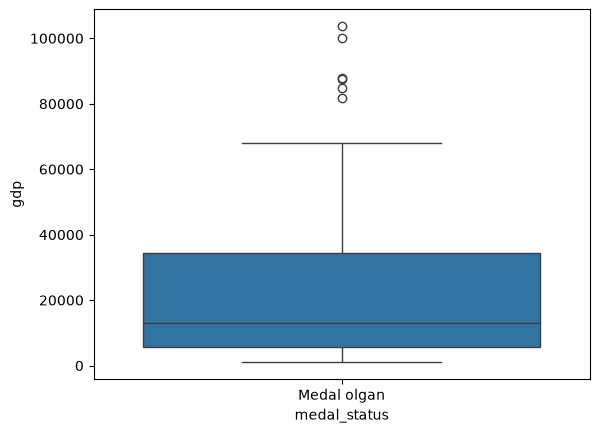

In [23]:
df['medal_status'] = df['total'].apply(
    lambda x: 'Medal olgan' if x > 0 else 'Medal olmagan'
)

sns.boxplot(x='medal_status', y='gdp', data=df)
plt.show()